In [72]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression

1. DataSet:

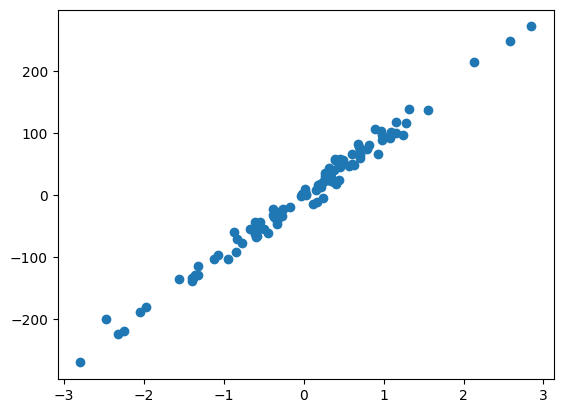

In [73]:
x,y = make_regression(n_samples=100,n_features=1,noise=10)
plt.scatter(x,y)

In [74]:
# Shape of x,y :
y = y.reshape(y.shape[0],1)
print(x.shape)
print(y.shape)

(100, 1)
(100, 1)


In [75]:
# Matrice X
X = np.hstack((x, np.ones(x.shape)))
X.shape

(100, 2)

In [76]:
# Theta 
theta = np.random.randn(2,1)
theta

array([[2.46506887],
       [0.40328935]])

2. Modèle:

In [77]:
def model(X,theta):
    return X.dot(theta) 

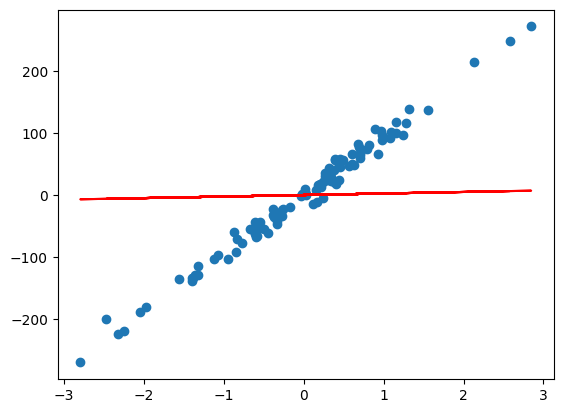

In [78]:
plt.scatter(x,y)
plt.plot(x,model(X,theta) , color='r')

3. Fonction cout:

In [79]:
def cost_function(X, y, theta):
    m = len(y)
    return 1/(2*m) * np.sum((model(X,theta) - y)**2)

In [80]:
float(cost_function(X,y,theta))

4290.59442757579

4. Gradient & Descente de Gradient :

In [81]:
def grad(X,y, theta):
    m = len(y)
    return 1/m * X.T.dot(model(X,theta) - y)

In [82]:
def gradien_descent(X,y,theta,alpha,n_iteration):
    cost_history = np.zeros(n_iteration)
    for _ in range(n_iteration):
        theta = theta - alpha * grad(X,y,theta)
        cost_history[_] = cost_function(X,y,theta)
    return theta,cost_history


5. Entrainement:

In [83]:
N = 1000
theta_final ,cost_history = gradien_descent(X,y,theta,0.01,N)

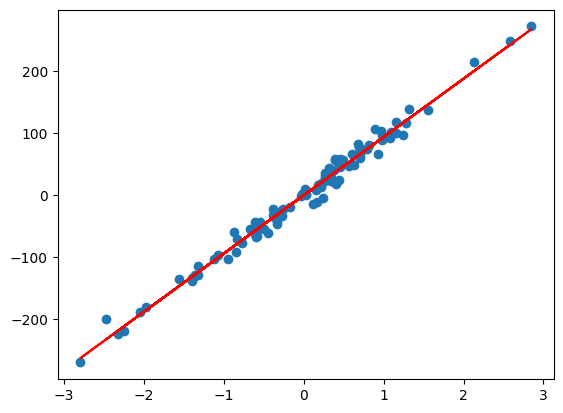

In [84]:
prediction = model(X,theta_final)
plt.scatter(x,y)
plt.plot(x,prediction, c = 'r')

6. Courbe d'apprentissage:

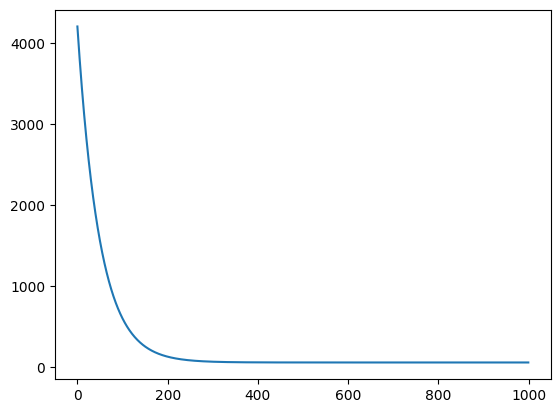

In [85]:
plt.plot(range(N), cost_history)

7. Coefficient de Determination

In [86]:
def coeff_determination(y,pred):
    U = ((y - pred)**2).sum()
    V = ((y - y.mean())**2).sum()
    return 1 - U/V

In [87]:
float(coeff_determination(y,prediction))

0.9864479326327187